# KDE Clusters — Identificación de hubs primarios y secundarios

Pipeline completo para extraer centroides de densidad de carga por estado usando KDE.

**Flujo:**
1. KDE por estado sobre `coordenadas3/` con normalización local
2. Extracción de familias de curvas de nivel (primarias `Z ≥ 0.8`, secundarias `0.3 ≤ Z < 0.8`)
3. Deduplicación espacial de centroides (radio 20 millas)
4. Correcciones manuales (NJ, RI, CT)
5. Exportación a `results/readykde.csv`

## Imports

In [1]:
import pandas as pd
import numpy as np
from statistics import mean
from matplotlib.path import Path
import matplotlib.colors as mcolors
import folium
import matplotlib.cm as cm
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from scipy.ndimage import maximum_filter, label
from shapely.geometry import Polygon, LineString
import base64
from io import BytesIO
import glob
import os
import copy

from metricas import coordenadas, cargasinout, haversine

## Constantes

In [2]:
cols = [
    'ID', 'Posted', 'PickUp', 'CityOrigin', 'CityDestination',
    'Distance', 'Equip', 'StateOrigin', 'HubOrigin',
    'StateDestination', 'HubDestination', 'Broker_Shipper', 'RatePerMile',
    'LatOrigin', 'LngOrigin', 'LatDestination', 'LngDestination'
]

## Funciones KDE y procesamiento de curvas

In [3]:
def generarkde(coords, col, bw=0.15, grid_res=100j, plot3d=False):
    x = coords['lng'].values
    y = coords['lat'].values
    weights = coords[col].values

    xy = np.vstack([x, y])
    kde = gaussian_kde(xy, weights=weights, bw_method=bw)

    xmin, xmax = x.min(), x.max()
    ymin, ymax = y.min(), y.max()
    X, Y = np.mgrid[xmin:xmax:grid_res, ymin:ymax:grid_res]
    positions = np.vstack([X.ravel(), Y.ravel()])
    Z = np.reshape(kde(positions).T, X.shape)

    if plot3d:
        fig = plt.figure(figsize=(10, 7))
        ax = fig.add_subplot(111, projection='3d')
        ax.plot_surface(X, Y, Z, cmap='viridis', linewidth=0, antialiased=True, alpha=0.8)
        ax.set_xlabel('Longitude')
        ax.set_ylabel('Latitude')
        ax.set_zlabel('Density')
        ax.view_init(elev=30, azim=-70)
        plt.show()

    return {
        'kde': kde,
        'X': X,
        'Y': Y,
        'Z': Z,
        'bounds': [[ymin, xmin], [ymax, xmax]]
    }


def extraer_curvas(X, Y, Z, n_niveles=20):
    fig, ax = plt.subplots()
    cs = ax.contour(X, Y, Z, levels=np.linspace(Z.min(), Z.max(), n_niveles))
    plt.close(fig)

    curvas = []
    for i, segs in enumerate(cs.allsegs):
        level = cs.levels[i]
        for seg in segs:
            curvas.append({'level': float(level), 'coords': seg.tolist()})

    z_max = np.nanmax(Z)
    idx_max = np.argwhere(Z == z_max)
    maximos = [{'Z': float(Z[i, j]), 'X': float(X[i, j]), 'Y': float(Y[i, j])} for i, j in idx_max]

    return curvas, maximos

def agrupar_familias(curvas):
    familias = []
    for curva in curvas:
        coords = curva['coords']
        if not coords:
            continue
        if coords[0] == coords[-1] and len(coords) >= 4:
            geom = Polygon(coords)
        else:
            geom = LineString(coords)

        agregado = False
        for familia in familias:
            for f in familia:
                if geom.intersects(f['geom']):
                    familia.append({'geom': geom, 'level': curva['level'], 'coords': coords})
                    agregado = True
                    break
            if agregado:
                break
        if not agregado:
            familias.append([{'geom': geom, 'level': curva['level'], 'coords': coords}])
    return familias

In [4]:
def clasificar_familias(familias, umbral=0.8, X=None, Y=None, Z=None):
    familias_status = {}

    for i, fam in enumerate(familias, 1):
        # 1. Primero calculamos zmax_coords (si tenemos X, Y, Z) para saber el pico real
        zmax_coords = []
        max_z_real = None  # Para almacenar el pico más alto de la familia
        
        if X is not None and Y is not None and Z is not None:
            mask = np.zeros_like(Z, dtype=bool)
            for curva in fam:
                poly = np.array(curva['coords'])
                if len(poly) < 3:
                    continue
                path = Path(poly)
                puntos = np.vstack((X.flatten(), Y.flatten())).T
                dentro = path.contains_points(puntos).reshape(X.shape)
                mask |= dentro

            Z_masked = np.where(mask, Z, np.nan)
            max_local = (Z_masked == maximum_filter(Z_masked, size=3))
            max_local[np.isnan(Z_masked)] = False
            labeled, n_labels = label(max_local)

            for n in range(1, n_labels + 1):
                idx = np.argwhere(labeled == n)
                if len(idx) == 0:
                    continue
                i_max, j_max = idx[0]
                z_val = float(Z[i_max, j_max])
                zmax_coords.append({
                    'Z': z_val,
                    'X': float(X[i_max, j_max]),
                    'Y': float(Y[i_max, j_max])
                })

        # 2. Determinamos el nivel_max real:
        # Priorizamos el Z máximo de los picos encontrados; si no hay, usamos las curvas.
        if zmax_coords:
            nivel_max = max([p['Z'] for p in zmax_coords])
        else:
            niveles = [curva['level'] for curva in fam]
            nivel_max = max(niveles) if niveles else 0.0

        # 3. Aplicamos tu regla de clasificación actualizada (ej: primaria >= 0.8, secundaria entre 0.4 y 0.8)
        if nivel_max >= 0.8:
            status = 'primaria'
        elif nivel_max >= 0.4:
            status = 'secundaria'
        else:
            status = 'terciaria'

        familias_status[f'familia_{i}'] = {
            'status': status,
            'nivel_max': nivel_max,
            'zmax_coords': zmax_coords,
            'curvas': [{'level': c['level'], 'coords': c['coords']} for c in fam]
        }

    return familias_status


def procesar_estado(res, n_niveles=20, umbral=0.8):
    X, Y, Z = res['X'], res['Y'], res['Z']
    curvas, maxs = extraer_curvas(X, Y, Z, n_niveles)
    familias = agrupar_familias(curvas)
    familias_status = clasificar_familias(familias, umbral, X, Y, Z)
    res['curvas'] = curvas
    res['familias'] = familias
    res['familias_status'] = familias_status
    return res


def clasificar_familias_secundarias(familias, umbral, X=None, Y=None, Z=None):
    familias_status = {}

    for i, fam in enumerate(familias, 1):
        zmax_coords = []
        
        # 1. Primero calculamos las coordenadas y valores de Z reales (picos)
        if X is not None and Y is not None and Z is not None:
            mask = np.zeros_like(Z, dtype=bool)
            for curva in fam:
                poly = np.array(curva['coords'])
                if len(poly) < 3:
                    continue
                path = Path(poly)
                puntos = np.vstack((X.flatten(), Y.flatten())).T
                dentro = path.contains_points(puntos).reshape(X.shape)
                mask |= dentro

            Z_masked = np.where(mask, Z, np.nan)
            max_local = (Z_masked == maximum_filter(Z_masked, size=3))
            max_local[np.isnan(Z_masked)] = False
            labeled, n_labels = label(max_local)

            for n in range(1, n_labels + 1):
                idx = np.argwhere(labeled == n)
                if len(idx) == 0:
                    continue
                i_max, j_max = idx[0]
                zmax_coords.append({
                    'Z': float(Z[i_max, j_max]),
                    'X': float(X[i_max, j_max]),
                    'Y': float(Y[i_max, j_max])
                })

        # 2. Definimos el nivel_max basándonos en los picos reales encontrados 
        # (o recurrimos a las curvas si no se pasaron matrices X, Y, Z)
        if zmax_coords:
            nivel_max = max([p['Z'] for p in zmax_coords])
        else:
            niveles = [curva['level'] for curva in fam]
            nivel_max = max(niveles) if niveles else 0.0

        # 3. Asignamos el estatus basado en el nivel_max real
        if nivel_max >= 0.8:
            status = 'primaria'
        elif nivel_max >= 0.4:
            status = 'secundaria'
        else:
            status = 'terciaria'

        familias_status[f'familia_{i}'] = {
            'status': status,
            'nivel_max': nivel_max,
            'zmax_coords': zmax_coords,
            'curvas': [{'level': c['level'], 'coords': c['coords']} for c in fam]
        }

    return familias_status

def procesar_estado_secundario(res, n_niveles=20, umbral=0.3):
    X, Y, Z = res['X'], res['Y'], res['Z']
    curvas, maxs = extraer_curvas(X, Y, Z, n_niveles)
    familias = agrupar_familias(curvas)
    familias_status = clasificar_familias_secundarias(familias, umbral, X, Y, Z)
    res['curvas'] = curvas
    res['familias'] = familias
    res['familias_status'] = familias_status
    return res

## Etapa 1 — KDE por estado y normalización

Carga cada parquet de `coordenadas3/`, aplica KDE ponderado por número de cargas y normaliza Z localmente (0–1 por estado).

In [5]:
carpeta = '../3. cleaning_coords/coordenadas'
archivos = glob.glob(os.path.join(carpeta, '*.parquet'))
resultados = {}

In [6]:
for i, archivo in enumerate(sorted(archivos), 1):
    df = pd.read_parquet(archivo)
    state = os.path.splitext(os.path.basename(archivo))[0]
    #print(i, state)
    coords = coordenadas(df, state)
    coords['cargas_log'] = np.log(coords['cargas'] + 1)
    resultados[state] = generarkde(coords, 'cargas_log')

print('KDE calculado para', len(resultados), 'estados')

KDE calculado para 48 estados


In [7]:
resultados_norm = {}

for state, data in resultados.items():
    Z = data['Z']
    Z_norm = Z / Z.max()
    resultados_norm[state] = {**data, 'Z': Z_norm}

print('Normalización completada')

Normalización completada


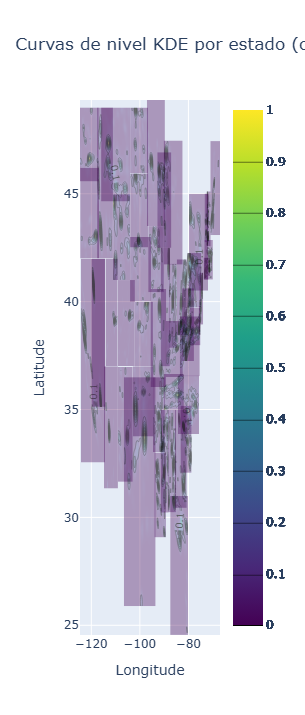

In [8]:
import plotly.graph_objects as go

fig = go.Figure()
Z
for state, res in resultados_norm.items():
    X, Y, Z = res["X"], res["Y"], res["Z"]

    fig.add_trace(go.Contour(
        x=X[:,0],
        y=Y[0,:],
        z=Z,
        contours=dict(
            showlines=True,        # dibuja las líneas
            coloring="heatmap",    # heatmap debajo
            showlabels=True,       # activa etiquetas
            labelfont=dict(        # estilo de etiquetas
                size=10,
                color="black"
            )
        ),
        colorscale="Viridis",
        opacity=0.6,
        name=state,
        showscale=True   # barra de colores global
    ))

fig.update_layout(
    title="Curvas de nivel KDE por estado (con etiquetas en Plotly)",
    xaxis_title="Longitude",
    yaxis_title="Latitude",
    legend_title="Estados",
    width=1000,
    height=700
)

fig.show()

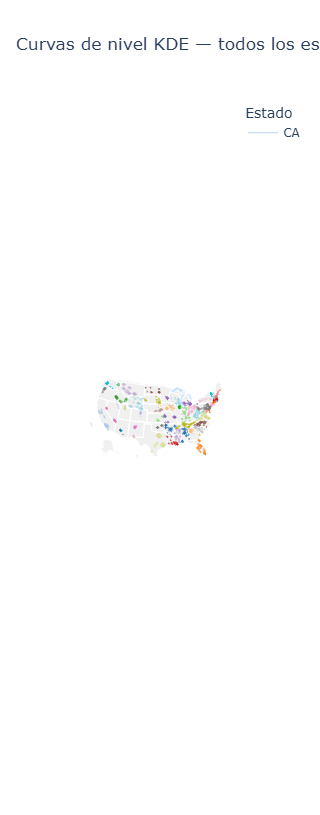

In [9]:
import plotly.graph_objects as go
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np

# Paleta automática para todos los estados
estados = list(resultados_norm.keys())
cmap = matplotlib.colormaps['tab20'].resampled(len(estados))
paleta = {state: f'rgba({int(cmap(i)[0]*255)},{int(cmap(i)[1]*255)},{int(cmap(i)[2]*255)},0.8)'
          for i, state in enumerate(estados)}

# ── Diagnóstico ──────────────────────────────────────────────────────────────
#print(f"{'Estado':6} | {'min Z':>7} | {'max Z':>7} | puntos > 0.8")
#print("-" * 40)
for state in estados:
    Z = resultados_norm[state]["Z"]
    #print(f"  {state:4} | {Z.min():>7.4f} | {Z.max():>7.4f} | {(Z > 0.8).sum():>5d}")

# ── Mapa ─────────────────────────────────────────────────────────────────────
fig = go.Figure()

for state in estados:
    res = resultados_norm[state]
    X, Y, Z = res["X"], res["Y"], res["Z"]
    lons = X[:, 0]
    lats = Y[0, :]

    fig_tmp, ax_tmp = plt.subplots()
    cs = ax_tmp.contour(lons, lats, Z.T, levels=8)
    plt.close(fig_tmp)

    color = paleta[state]
    primer_trace = True

    for level_val, segs in zip(cs.levels, cs.allsegs):
        for seg in segs:
            fig.add_trace(go.Scattergeo(
                lon=seg[:, 0],
                lat=seg[:, 1],
                mode='lines',
                line=dict(color=color, width=1),
                name=state,
                legendgroup=state,
                showlegend=primer_trace,
                hovertemplate=(
                    f"<b>{state}</b><br>"
                    f"KDE: {level_val:.4f}<br>"
                    "Lon: %{lon:.3f}<br>"
                    "Lat: %{lat:.3f}<extra></extra>"
                )
            ))
            primer_trace = False

fig.update_layout(
    title="Curvas de nivel KDE — todos los estados",
    geo=dict(
        scope='usa',
        projection_type='albers usa',
        showland=True,       landcolor='#f0f0f0',
        showlakes=True,      lakecolor='#cce5ff',
        showsubunits=True,   subunitcolor='white',
        showcoastlines=True, coastlinecolor='gray',
    ),
    width=1400,
    height=800,
    legend_title="Estado",
)

fig.show()

In [10]:
# juntar todos los Z en un solo array
all_Z = np.concatenate([data['Z'].ravel() for data in resultados_norm.values()])

# 🔹 Histograma
plt.figure(figsize=(8,5))
plt.hist(all_Z, bins=50, density=True, alpha=0.7, color="steelblue")
plt.xlabel("Valor de Z normalizado")
plt.ylabel("Densidad de frecuencia")
plt.title("Histograma de Z (todos los estados)")
plt.show()

# 🔹 Describe
desc_all = pd.Series(all_Z).describe()
print(desc_all)

count    480000.000000
mean          0.061786
std           0.114094
min           0.000000
25%           0.000942
50%           0.019492
75%           0.071020
max           1.000000
dtype: float64


## Etapa 2 — Extracción de familias primarias (Z ≥ 0.8)

Para cada estado, extrae curvas de nivel, agrupa en familias y clasifica. Las familias con pico normalizado ≥ 0.8 son **primarias**.

In [11]:
for state, res in resultados_norm.items():
    #print(state)
    resultados_norm[state] = procesar_estado(res, n_niveles=20, umbral=0.8)

print('Familias primarias procesadas')

Familias primarias procesadas


Por familia primaria, se toman los puntos con Z ≥ 0.8 y se deduplican a 20 millas (se queda el de mayor Z). NJ, RI y CT reciben coordenadas fijas por ser estados pequeños con poca variación geográfica.

In [12]:
state = 'WY'
if state in resultados_norm and 'familias_status' in resultados_norm[state]:
    print(f"=== RESUMEN DE FAMILIAS PARA: {state} ===")
    familias_status = resultados_norm[state]['familias_status']
    
    for fam_id, data in familias_status.items():
        print(f"• {fam_id.capitalize()}:")
        print(f"    - Estado/Clasificación: {data['status']}")
        print(f"    - Nivel Máximo: {data['nivel_max']:.4f}")
        print(f"    - Cantidad de picos (zmax): {len(data['zmax_coords'])}")
        print(f"    - Total de curvas de nivel: {len(data['curvas'])}")
else:
    print(f"No se encontraron datos procesados para el estado {state}.")

=== RESUMEN DE FAMILIAS PARA: WY ===
• Familia_1:
    - Estado/Clasificación: terciaria
    - Nivel Máximo: 0.0023
    - Cantidad de picos (zmax): 0
    - Total de curvas de nivel: 1
• Familia_2:
    - Estado/Clasificación: primaria
    - Nivel Máximo: 0.8347
    - Cantidad de picos (zmax): 3
    - Total de curvas de nivel: 1
• Familia_3:
    - Estado/Clasificación: terciaria
    - Nivel Máximo: 0.2798
    - Cantidad de picos (zmax): 2
    - Total de curvas de nivel: 1
• Familia_4:
    - Estado/Clasificación: terciaria
    - Nivel Máximo: 0.0548
    - Cantidad de picos (zmax): 0
    - Total de curvas de nivel: 1
• Familia_5:
    - Estado/Clasificación: terciaria
    - Nivel Máximo: 0.2934
    - Cantidad de picos (zmax): 4
    - Total de curvas de nivel: 1
• Familia_6:
    - Estado/Clasificación: terciaria
    - Nivel Máximo: 0.0548
    - Cantidad de picos (zmax): 8
    - Total de curvas de nivel: 1
• Familia_7:
    - Estado/Clasificación: terciaria
    - Nivel Máximo: 0.2953
    - Cant

In [13]:
DIST_THRESHOLD = 50  # millas
centroides2 = []

for state, res in resultados_norm.items():
    X, Y, Z = res['X'], res['Y'], res['Z']
    familias_status = res.get('familias_status', {})

    for fam_id, info in familias_status.items():
        if info['status'] != 'primaria':
            continue

        zmax_list = info.get('zmax_coords', [])
        zmax_sorted = sorted(zmax_list, key=lambda x: x.get('Z', 0), reverse=True)
        filtered_points = []

        for zmax in zmax_sorted:
            if zmax.get('Z', 0) < 0.8:
                continue
            lat, lon = zmax['Y'], zmax['X']

            too_close = False
            for kept in filtered_points:
                if haversine(lat, lon, kept['point'][0], kept['point'][1]) < DIST_THRESHOLD:
                    too_close = True
                    break

            if not too_close:
                filtered_points.append({
                    'point': (lat, lon),
                    'Z': zmax['Z'],
                    'state': state,
                    'fam_id': fam_id
                })

        centroides2.extend(filtered_points)

print(f'Centroides primarios extraídos: {len(centroides2)}')

Centroides primarios extraídos: 243


In [14]:
wy_centroides2 = [r for r in centroides2 if r['state'] == 'DE']
print(f'\nWY primarios en centroides2: {len(wy_centroides2)}')
for r in wy_centroides2:
    print(f"  {r['fam_id']} | lat={r['point'][0]:.4f} lng={r['point'][1]:.4f} Z={r['Z']:.4f}")


WY primarios en centroides2: 7
  familia_9 | lat=39.7191 lng=-75.5451 Z=1.0000
  familia_16 | lat=39.7191 lng=-75.5451 Z=1.0000
  familia_20 | lat=39.7191 lng=-75.5451 Z=1.0000
  familia_21 | lat=39.7191 lng=-75.5451 Z=1.0000
  familia_23 | lat=39.7191 lng=-75.5451 Z=1.0000
  familia_26 | lat=39.7191 lng=-75.5451 Z=1.0000
  familia_27 | lat=39.7191 lng=-75.5451 Z=1.0000


In [15]:
import folium

m = folium.Map(location=[39.5, -98.35], zoom_start=5, tiles="OpenStreetMap")

for row in centroides2:
    lat, lng = row['point']
    folium.CircleMarker(
        location=[lat, lng],
        radius=3,
        color='red', fill=True, fill_color='red', fill_opacity=0.8,
        popup=f"{row['fam_id']} ({row['state']}) Z={row['Z']:.2f}"
    ).add_to(m)

colores = {'primaria': 'red', 'secundaria': 'blue'}

for row in centroides2:
    lat, lng = row['point']
    cat = row.get('categoría', 'primaria')
    color = colores.get(cat, 'gray')
    folium.CircleMarker(
        location=[lat, lng],
        radius=3,
        color=color, fill=True, fill_color=color, fill_opacity=0.8,
        popup=f"{row['fam_id']} ({row['state']}) Z={row['Z']:.2f}"
    ).add_to(m)

m

#### Correcciones manuales para NJ, RI, CT

Estos estados son tan pequeños que el KDE no distingue bien un centroide único. Se fijan coordenadas manualmente.

In [16]:
central_cities = {
    'NJ': {'city': 'New Brunswick (NJ)', 'lat': 40.4862, 'lng': -74.4518},
    'RI': {'city': 'Providence (RI)',    'lat': 41.8240, 'lng': -71.4128},
    'CT': {'city': 'Hartford (CT)',      'lat': 41.7658, 'lng': -72.6734},
}

rows = []
id_counter = 1
usados = set()

for entry in centroides2:
    state = entry['state']
    if state in central_cities:
        if state not in usados:
            city = central_cities[state]
            rows.append({
                'id': id_counter, 'lat': city['lat'], 'lng': city['lng'],
                'Z': 1.0, 'new_name': city['city'],
                'state': state, 'fam_id': f"familia_{state.lower()}",
                'categoría': 'primaria'
            })
            usados.add(state)
            id_counter += 1
    else:
        lat, lng = entry['point']
        rows.append({
            'id': id_counter, 'lat': lat, 'lng': lng,
            'Z': entry['Z'], 'new_name': f"Pico {state}",
            'state': state, 'fam_id': entry.get('fam_id'),
            'categoría': 'primaria'
        })
        id_counter += 1

df_picos = pd.DataFrame(rows)
print(df_picos.shape)
df_picos.head()

(234, 8)


,id,lat,lng,Z,new_name,state,fam_id,categoría
0,1,33.455575,-86.839677,1.000000,Pico AL,AL,familia_14,primaria
1,2,33.455575,-86.839677,1.000000,Pico AL,AL,familia_24,primaria
2,3,34.739338,-92.289498,1.000000,Pico AR,AR,familia_11,primaria
3,4,36.218294,-94.151811,0.894564,Pico AR,AR,familia_13,primaria
4,5,36.218294,-94.151811,0.894564,Pico AR,AR,familia_24,primaria


### Deduplicación final de primarios (50 millas)

In [17]:
max_dist = 50
df_filtrado = df_picos.reset_index(drop=True)
eliminados = set()
keep_indices = []

In [18]:
estados_fijos = {'NJ', 'RI', 'CT'}

# Paso 1: los fijos siempre se quedan y nunca eliminan a nadie
fijos_idx = df_filtrado[df_filtrado['state'].isin(estados_fijos)].index.tolist()
keep_indices = list(fijos_idx)
eliminados = set()

# Paso 2: deduplicar solo entre no-fijos
no_fijos_idx = df_filtrado[~df_filtrado['state'].isin(estados_fijos)].index.tolist()

for i in no_fijos_idx:
    if i in eliminados:
        continue
    lat1, lon1 = df_filtrado.loc[i, ['lat', 'lng']]
    cercanos = [i]
    for j in no_fijos_idx:
        if j <= i or j in eliminados:
            continue
        lat2, lon2 = df_filtrado.loc[j, ['lat', 'lng']]
        if haversine(lat1, lon1, lat2, lon2) <= max_dist:
            cercanos.append(j)

    idx_max = df_filtrado.loc[cercanos, 'Z'].idxmax()
    keep_indices.append(idx_max)
    eliminados.update(cercanos)

In [19]:
wy_final = df_filtrado.loc[keep_indices]
wy_final = wy_final[wy_final['state'] == 'WY']
print(f'WY primarios tras dedup global: {len(wy_final)}')
print(wy_final[['fam_id', 'lat', 'lng', 'Z']])

WY primarios tras dedup global: 2
         fam_id        lat         lng         Z
218   familia_2  42.852061 -106.315806  0.834667
220  familia_21  41.128321 -104.833819  1.000000


In [20]:
eliminados_idx = set(range(len(df_filtrado))) - set(keep_indices)
df_eliminados = df_filtrado.loc[sorted(eliminados_idx)]
print(df_eliminados[['state', 'lat', 'lng', 'Z', 'new_name']])

    state        lat         lng         Z new_name
1      AL  33.455575  -86.839677  1.000000  Pico AL
4      AR  36.218294  -94.151811  0.894564  Pico AR
5      AR  34.739338  -92.289498  1.000000  Pico AR
6      AR  36.218294  -94.151811  0.894564  Pico AR
7      AR  36.218294  -94.151811  0.894564  Pico AR
..    ...        ...         ...       ...      ...
229    WY  41.128321 -104.833819  1.000000  Pico WY
230    WY  41.128321 -104.833819  1.000000  Pico WY
231    WY  41.128321 -104.833819  1.000000  Pico WY
232    WY  41.128321 -104.833819  1.000000  Pico WY
233    WY  41.128321 -104.833819  1.000000  Pico WY

[177 rows x 5 columns]


In [21]:
df_final = df_filtrado.loc[keep_indices].reset_index(drop=True)
print(f'Centroides primarios tras dedup: {len(df_final)}')
df_final.head()

Centroides primarios tras dedup: 57


,id,lat,lng,Z,new_name,state,fam_id,categoría
0,17,41.765800,-72.673400,1.0,Hartford (CT),CT,familia_ct,primaria
1,116,40.486200,-74.451800,1.0,New Brunswick (NJ),NJ,familia_nj,primaria
2,156,41.824000,-71.412800,1.0,Providence (RI),RI,familia_ri,primaria
3,1,33.455575,-86.839677,1.0,Pico AL,AL,familia_14,primaria
4,3,34.739338,-92.289498,1.0,Pico AR,AR,familia_11,primaria


### Guardar centroides primarios

In [22]:
import os
os.makedirs('results', exist_ok=True)
df_final.to_csv('results/clusters_primarios.csv', index=False)
print('Guardado: results/clusters_primarios.csv')

Guardado: results/clusters_primarios.csv


## Etapa 3 — Extracción de familias secundarias (0.3 ≤ Z < 0.8)

Se excluyen las familias primarias ya extraídas y se reprocesa con umbral 0.3 para capturar zonas de densidad media.

In [23]:
cp = pd.read_csv('results/clusters_primarios.csv')
familias_excluir = cp.groupby('state')['fam_id'].apply(set).to_dict()

familias_secundarias_data = copy.deepcopy(resultados_norm)

for state, res in familias_secundarias_data.items():
    familias_status = res.get('familias_status', {})
    if state in familias_excluir:
        excluir = familias_excluir[state]
        familias_status = {fid: info for fid, info in familias_status.items() if fid not in excluir}
        res['familias_status'] = familias_status
    familias_secundarias_data[state] = res

print('Familias primarias excluidas')

Familias primarias excluidas


In [24]:
for state, res in familias_secundarias_data.items():
    print(state)
    familias_secundarias_data[state] = procesar_estado_secundario(res, n_niveles=20, umbral=0.3)

print('Familias secundarias procesadas')

AL
AR
AZ
CA
CO
CT
DE
FL
GA
IA
ID
IL
IN
KS
KY
LA
MA
MD
ME
MI
MN
MO
MS
MT
NC
ND
NE
NH
NJ
NM
NV
NY
OH
OK
OR
PA
RI
SC
SD
TN
TX
UT
VA
VT
WA
WI
WV
WY
Familias secundarias procesadas


In [25]:
state = 'WY'
if state in familias_secundarias_data and 'familias_status' in familias_secundarias_data[state]:
    print(f"=== RESUMEN DE FAMILIAS PARA: {state} ===")
    familias_status = familias_secundarias_data[state]['familias_status']
    print(familias_status)
    
    for fam_id, data in familias_status.items():
        print(f"• {fam_id.capitalize()}:")
        print(f"    - Estado/Clasificación: {data['status']}")
        print(f"    - Nivel Máximo: {data['nivel_max']:.4f}")
        print(f"    - Cantidad de picos (zmax): {len(data['zmax_coords'])}")
        
        # Mostrar el detalle de las coordenadas zmax
        print(f"    - Coordenadas (zmax):")
        for i, coord in enumerate(data['zmax_coords'], 1):
            print(f"        {i}. X: {coord.get('X')}, Y: {coord.get('Y')} (Z: {coord.get('Z')})")
            
        print(f"    - Total de curvas de nivel: {len(data['curvas'])}")

else:
    print(f"No se encontraron datos procesados para el estado {state}.")

=== RESUMEN DE FAMILIAS PARA: WY ===
{'familia_1': {'status': 'terciaria', 'nivel_max': 0.0023310824722413935, 'zmax_coords': [], 'curvas': [{'level': 0.0023310824722413935, 'coords': [[-111.04405, 44.415452424242424], [-111.04405, 44.415452424242424], [-111.04405, 44.415452424242424]]}]}, 'familia_2': {'status': 'primaria', 'nivel_max': 0.8346666749628682, 'zmax_coords': [{'Z': 0.8346666749628682, 'X': -106.31580585858586, 'Y': 42.852060606060604}, {'Z': 0.05075678248056763, 'X': -105.39838535353536, 'Y': 42.05032121212121}, {'Z': 0.054355496739464916, 'X': -105.32781454545454, 'Y': 41.88997333333333}], 'curvas': [{'level': 0.054839972868439224, 'coords': [[-111.04405, 41.56773654828967], [-111.03973806528047, 41.569277575757575], [-110.97347919191918, 41.60205789334763], [-110.96085312324614, 41.60936454545454], [-110.92411366127962, 41.64945151515151], [-110.9127341500067, 41.689538484848484], [-110.91449868298658, 41.729625454545456], [-110.92169687427605, 41.769712424242414], [-11

In [26]:
#familia_22 - sec
#familia_17 - sec
#familia_42 - primaria

Se toman los puntos Zmax de familias con `status == 'secundaria'` (0.3 ≤ Z < 0.8).

In [27]:
z_pintados = []

for state, res in familias_secundarias_data.items():
    familias_status = res.get('familias_status', {})
    
    # Imprimir inicio del procesamiento para WY
    if state == 'WY':
        print(familias_status)
        
        print(f"\n--- Evaluando datos para el estado: {state} ---")
        print(f"Total de familias encontradas en {state}: {len(familias_status)}")

    for fam_id, info in familias_status.items():
        status = info.get('status')
        
        if status != 'secundaria':
            if state == 'WY':
                print(f"  [DESCARTADO] {fam_id}: status '{status}' != 'secundaria'")
            continue
        
        coords = info.get('zmax_coords', [])
        if state == 'WY' and not coords:
            print(f"  [AVISO] {fam_id}: Es secundaria pero no tiene zmax_coords")

        for p in coords:
            z_val = p.get('Z', 0)
            
            if z_val < 0.4 or z_val >= 0.8:
                if state == 'WY':
                    print(f"  [DESCARTADO] {fam_id} -> Punto (Lon: {p['X']}, Lat: {p['Y']}): Z = {z_val:.4f} fuera de rango [0.4, 0.8)")
                continue
            
            if state == 'WY':
                print(f"  [ACEPTADO] {fam_id} -> Punto (Lon: {p['X']}, Lat: {p['Y']}): Z = {z_val:.4f}")

            z_pintados.append({
                'state': state,
                'family': fam_id,
                'lat': p['Y'],
                'lon': p['X'],
                'Z': p['Z']
            })

print(f'\nPuntos secundarios candidatos: {len(z_pintados)}')

{'familia_1': {'status': 'terciaria', 'nivel_max': 0.0023310824722413935, 'zmax_coords': [], 'curvas': [{'level': 0.0023310824722413935, 'coords': [[-111.04405, 44.415452424242424], [-111.04405, 44.415452424242424], [-111.04405, 44.415452424242424]]}]}, 'familia_2': {'status': 'primaria', 'nivel_max': 0.8346666749628682, 'zmax_coords': [{'Z': 0.8346666749628682, 'X': -106.31580585858586, 'Y': 42.852060606060604}, {'Z': 0.05075678248056763, 'X': -105.39838535353536, 'Y': 42.05032121212121}, {'Z': 0.054355496739464916, 'X': -105.32781454545454, 'Y': 41.88997333333333}], 'curvas': [{'level': 0.054839972868439224, 'coords': [[-111.04405, 41.56773654828967], [-111.03973806528047, 41.569277575757575], [-110.97347919191918, 41.60205789334763], [-110.96085312324614, 41.60936454545454], [-110.92411366127962, 41.64945151515151], [-110.9127341500067, 41.689538484848484], [-110.91449868298658, 41.729625454545456], [-110.92169687427605, 41.769712424242414], [-110.92982741256014, 41.80979939393939],

In [28]:
z_pintados = []

for state, res in familias_secundarias_data.items():
    familias_status = res.get('familias_status', {})
    for fam_id, info in familias_status.items():
        if info.get('status') != 'secundaria':
            continue
        for p in info.get('zmax_coords', []):
            if p['Z'] < 0.4 or p['Z'] >= 0.8:
                continue
            z_pintados.append({
                'state': state,
                'family': fam_id,
                'lat': p['Y'],
                'lon': p['X'],
                'Z': p['Z']
            })

print(f'Puntos secundarios candidatos: {len(z_pintados)}')

Puntos secundarios candidatos: 126


In [29]:
z_pintados

[{'state': 'AL',
  'family': 'familia_12',
  'lat': 30.718924950505052,
  'lon': -88.10688717171718,
  'Z': 0.5837079630837362},
 {'state': 'AL',
  'family': 'familia_18',
  'lat': 32.39932412727273,
  'lon': -86.31167274747474,
  'Z': 0.4360661417113468},
 {'state': 'AL',
  'family': 'familia_22',
  'lat': 30.718924950505052,
  'lon': -88.10688717171718,
  'Z': 0.5837079630837362},
 {'state': 'AR',
  'family': 'familia_19',
  'lat': 35.830948585858586,
  'lon': -90.62321736363636,
  'Z': 0.408008561816058},
 {'state': 'AR',
  'family': 'familia_22',
  'lat': 35.373176565656564,
  'lon': -94.34784378787879,
  'Z': 0.5779756085967486},
 {'state': 'AR',
  'family': 'familia_27',
  'lat': 35.373176565656564,
  'lon': -94.34784378787879,
  'Z': 0.5779756085967486},
 {'state': 'AR',
  'family': 'familia_29',
  'lat': 35.373176565656564,
  'lon': -94.34784378787879,
  'Z': 0.5779756085967486},
 {'state': 'AR',
  'family': 'familia_31',
  'lat': 35.373176565656564,
  'lon': -94.34784378787879

In [30]:
wy_candidatos = [r for r in z_pintados if r['state'] == 'WY']
print(f'WY candidatos secundarios: {len(wy_candidatos)}')
for r in wy_candidatos:
    print(f"  lat={r['lat']:.4f} lng={r['lon']:.4f} Z={r['Z']:.4f}")

WY candidatos secundarios: 2
  lat=41.5693 lng=-109.3504 Z=0.4679
  lat=41.5693 lng=-109.3504 Z=0.4679


In [31]:
m = folium.Map(location=[39.5, -98.35], zoom_start=5, tiles="OpenStreetMap")

for row in z_pintados:
    folium.CircleMarker(
        location=[row['lat'], row['lon']],
        radius=4,
        color='blue', fill=True, fill_color='blue', fill_opacity=0.8,
        popup=f"{row['family']} ({row['state']}) Z={row['Z']:.2f}"
    ).add_to(m)

m

In [32]:
id_counter = cp.shape[0] + 1
rows = []

for entry in z_pintados:
    rows.append({
        'id': id_counter,
        'lat': entry['lat'],
        'lng': entry['lon'],
        'Z': entry['Z'],
        'new_name': f"Pico {entry['state']}",
        'state': entry['state'],
        'fam_id': entry['family'],
        'categoría': 'secundaria'
    })
    id_counter += 1

df_picos2 = pd.DataFrame(rows)
print(df_picos2.shape)

(126, 8)


Eliminaremos redundancia de clusters primero entre secundarios y primarios, luego entre clusters secundarios.

In [33]:
df = pd.concat([cp, df_picos2]).reset_index(drop=True)
df = df.drop_duplicates(['lat', 'lng'])
print(f'Total combinado: {df.shape[0]}')

Total combinado: 123


In [34]:
RADIUS_MILES = 75
primarios = df[df['categoría'] == 'primaria'].reset_index(drop=True)
to_remove = set()

for i, row_p in primarios.iterrows():
    for j, row_o in df.iterrows():
        if j == row_p.name:
            continue
        if row_o['categoría'] == 'primaria':
            continue
        if haversine(row_p['lat'], row_p['lng'], row_o['lat'], row_o['lng']) <= RADIUS_MILES:
            to_remove.add(j)

df_final_centroides = df.drop(index=to_remove).reset_index(drop=True)
print(f'Eliminados por radio primario: {len(to_remove)}')
print(f'Centroides restantes: {len(df_final_centroides)}')

Eliminados por radio primario: 33
Centroides restantes: 90


In [35]:
secundarios = df_final_centroides.loc[df_final_centroides['categoría']=='secundaria']
secundarios.shape

(33, 8)

In [36]:
for idx, row in secundarios.iterrows():
    folium.CircleMarker(
        location=[row['lat'], row['lng']],
        radius=4,
        color='blue',
        fill=True,
        fill_color='blue',
        fill_opacity=0.8,
        popup=f"{row['fam_id']} ({row['state']}) Z={row['Z']:.2f}"
    ).add_to(m)

m

In [37]:
DIST_SEC = 50  # millas

# Filtrar centroides secundarios
secundarios = df_final_centroides.loc[
    df_final_centroides['categoría'] == 'secundaria'
].copy()

# Ordenar de mayor a menor Z
secundarios = secundarios.sort_values('Z', ascending=False)

keep_sec = []
removed_sec = []

for row in secundarios.itertuples(index=False):
    candidate = {
        'lat': row.lat,
        'lng': row.lng,
        'Z': row.Z,
        'state': row.state,
        'fam_id': row.fam_id
    }

    too_close = False

    for kept in keep_sec:
        if haversine(
            candidate['lat'], candidate['lng'],
            kept['lat'], kept['lng']
        ) < DIST_SEC:
            too_close = True
            break

    if not too_close:
        keep_sec.append(candidate)
    else:
        removed_sec.append(candidate)

print(f'Secundarios antes: {len(secundarios)}')
print(f'Secundarios tras dedup 50 mi: {len(keep_sec)}')
print(f'Eliminados: {len(removed_sec)}')
print()

for r in removed_sec:
    print(
        f"  {r['state']:4} | {r['fam_id']:12} | "
        f"lat={r['lat']:.4f} lng={r['lng']:.4f} | Z={r['Z']:.4f}"
    )

Secundarios antes: 33
Secundarios tras dedup 50 mi: 31
Eliminados: 2

  FL   | familia_9    | lat=28.0006 lng=-81.9982 | Z=0.4387
  WI   | familia_16   | lat=44.4635 lng=-88.0657 | Z=0.4294


In [38]:
id_counter = cp.shape[0] + 1
rows = []

for entry in keep_sec:
    rows.append({
        'id': id_counter,
        'lat': entry['lat'],
        'lng': entry['lng'],
        'Z': entry['Z'],
        'new_name': f"Pico {entry['state']}",
        'state': entry['state'],
        'fam_id': entry['fam_id'],
        'categoría': 'secundaria'
    })
    id_counter += 1

df_picos2 = pd.DataFrame(rows)
print(df_picos2.shape)

(31, 8)


In [39]:
df_picos2.loc[df_picos2['categoría']=='secundaria'].to_csv('results/clusters_secundarios.csv', index=False)
print('Guardado: results/clusters_secundarios.csv')

Guardado: results/clusters_secundarios.csv


## Etapa 5 — Exportar `readykde.csv`

In [40]:
df_final_centroides = pd.concat([cp, df_picos2]).reset_index(drop=True)
df_final_centroides = df_final_centroides.drop_duplicates(['lat', 'lng'])
print(f'Total combinado: {df_final_centroides.shape[0]}')

Total combinado: 88


In [41]:
df_final_centroides.to_csv('results/clusters_kde.csv', index=False)
print('Guardado: results/clusters_kde.csv')
df_final_centroides.groupby('categoría')['state'].count()

Guardado: results/clusters_kde.csv


categoría
primaria      57
secundaria    31
Name: state, dtype: int64

## Visualización final

In [42]:
#hubs = pd.read_excel('../utils/hubs_id.xlsx')

m = folium.Map(location=[39.5, -98.35], zoom_start=5, tiles="OpenStreetMap")

for _, row in df_final_centroides[df_final_centroides['categoría'] == 'primaria'].iterrows():
    folium.CircleMarker(
        location=[row['lat'], row['lng']], radius=3,
        color='red', fill=True, fill_color='red', fill_opacity=0.8,
        popup=f"{row['new_name']} ({row['state']}) Z={row['Z']:.2f}"
    ).add_to(m)

for _, row in df_final_centroides[df_final_centroides['categoría'] == 'secundaria'].iterrows():
    folium.CircleMarker(
        location=[row['lat'], row['lng']], radius=3,
        color='blue', fill=True, fill_color='blue', fill_opacity=0.8,
        popup=f"{row['new_name']} ({row['state']}) Z={row['Z']:.2f}"
    ).add_to(m)

legend_html = (
    '<div style="position:fixed;bottom:30px;left:30px;width:170px;background:white;' +
    'border:2px solid grey;border-radius:8px;padding:10px;z-index:9999;font-size:14px">' +
    '<b>Tipo de hub</b><br>' +
    '<span style="color:red;font-size:18px">&#9679;</span> Primaria<br>' +
    '<span style="color:blue;font-size:18px">&#9679;</span> Secundaria</div>'
)

m.get_root().html.add_child(folium.Element(legend_html))
m